# Air Quality Time Series Forecasting (India)

**Goal:** Forecast the daily Air Quality Index (AQI) of an Indian city and compare simple baselines, a statistical model (ARIMA), and machine-learning models.

**Dataset:** [Air Quality Data in India (2015-2020)](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india) - file `city_day.csv`

**Skills shown:** Pandas, NumPy, data cleaning, EDA, time series (decomposition, stationarity, ARIMA), feature engineering, scikit-learn, model evaluation.

**Notebook outline**
1. Setup and load data
2. Data cleaning
3. Exploratory data analysis (EDA)
4. Time series analysis for one city
5. Baseline models
6. ARIMA model
7. Machine learning models with lag features
8. Compare all models
9. Forecast the next 7 days
10. Conclusions

## 1. Setup and load data



In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("data/city_day.csv", parse_dates=["Date"])
print("Shape:", df.shape)
df.head()

Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  str           
 1   Date        29531 non-null  datetime64[us]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  str           
dtypes: datetime64[us](1), float64(13)

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


## 2. Data cleaning

Real data is messy. Let's check how much is missing before deciding what to do.

In [5]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).round(1)
missing.to_frame("missing_%")

,missing_%
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
AQI_Bucket,15.9
PM2.5,15.6
NOx,14.2
O3,13.6


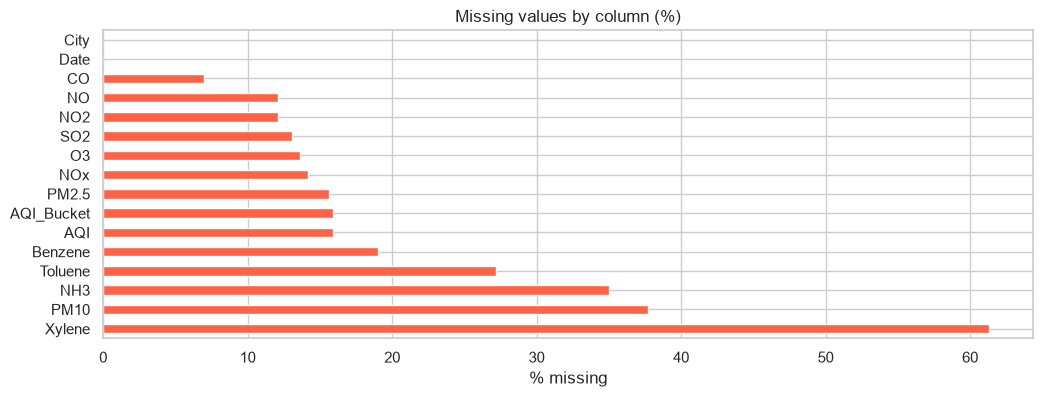

In [6]:
missing.plot(kind="barh", color="tomato", title="Missing values by column (%)")
plt.xlabel("% missing")
plt.show()

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Cities:", df["City"].nunique())

# Rows where the target (AQI) is missing cannot be used for supervised learning
print("Rows with missing AQI:", df["AQI"].isna().sum())
aqi_coverage = df.groupby("City")["AQI"].apply(lambda s: s.notna().sum()).sort_values(ascending=False)
aqi_coverage.head(10)

Duplicate rows: 0
Date range: 2015-01-01 to 2020-07-01
Cities: 26
Rows with missing AQI: 4681


City
Delhi            1999
Bengaluru        1910
Lucknow          1893
Chennai          1884
Hyderabad        1880
Patna            1459
Gurugram         1453
Ahmedabad        1334
Visakhapatnam    1171
Amritsar         1126
Name: AQI, dtype: int64

**Observation:** Several pollutant columns (Xylene, PM10, NH3 ...) have many missing values, and not every city has full AQI coverage. We will pick a city with good coverage for the time-series modelling.

## 3. Exploratory Data Analysis (EDA)

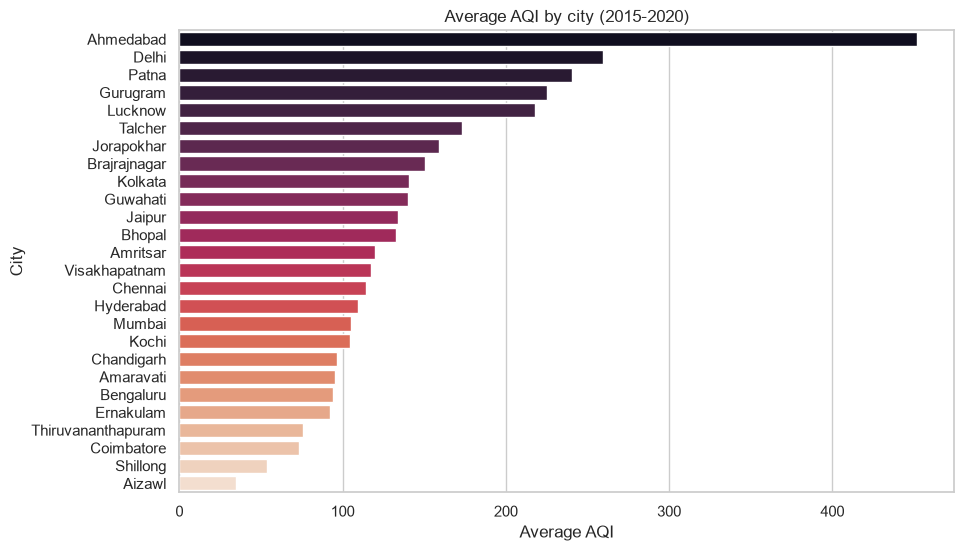

In [8]:
# Which cities have the worst air on average?
city_avg = df.groupby("City")["AQI"].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=city_avg.values, y=city_avg.index, palette="rocket")
plt.title("Average AQI by city (2015-2020)")
plt.xlabel("Average AQI")
plt.show()

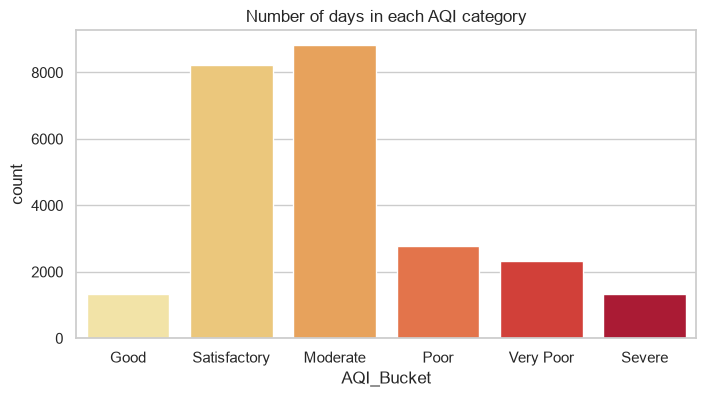

In [9]:
# AQI category distribution
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="AQI_Bucket", order=order, palette="YlOrRd")
plt.title("Number of days in each AQI category")
plt.show()

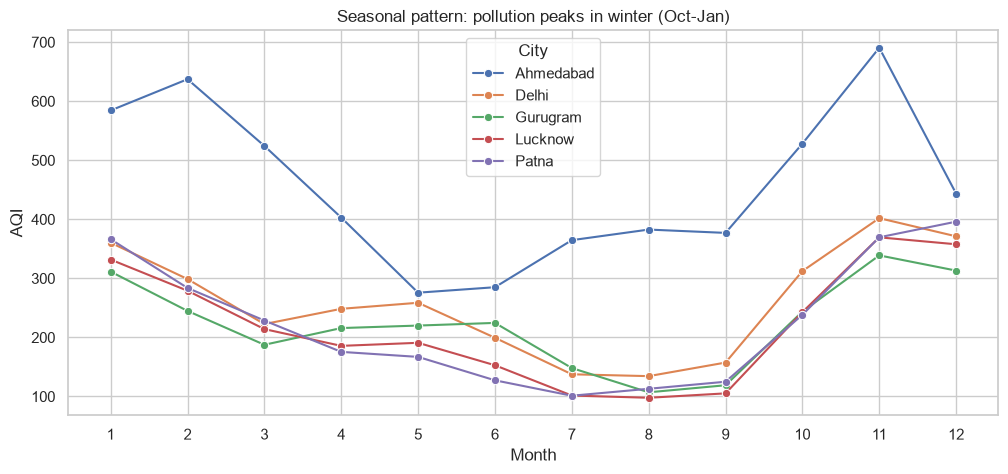

In [10]:
# Seasonality: average AQI by month for the 5 most polluted cities
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
top5 = city_avg.head(5).index
monthly = df[df["City"].isin(top5)].groupby(["Month", "City"])["AQI"].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="Month", y="AQI", hue="City", marker="o")
plt.xticks(range(1, 13))
plt.title("Seasonal pattern: pollution peaks in winter (Oct-Jan)")
plt.show()

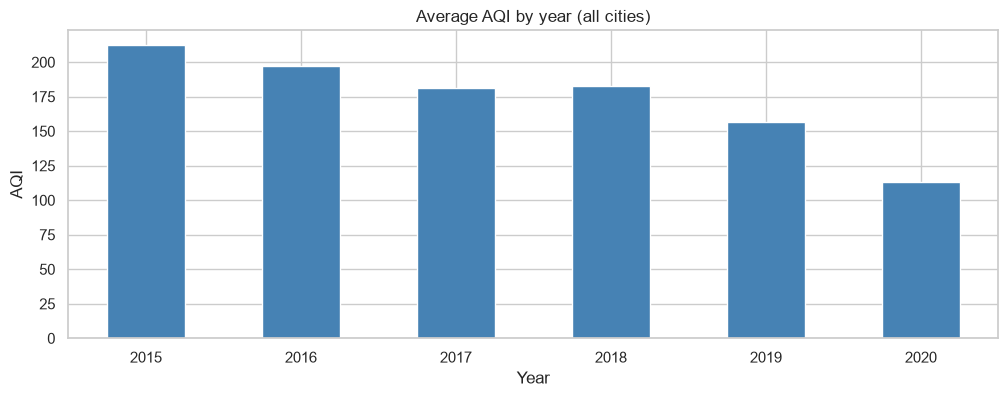

In [11]:
# Yearly trend
yearly = df.groupby("Year")["AQI"].mean()
yearly.plot(kind="bar", color="steelblue", title="Average AQI by year (all cities)")
plt.ylabel("AQI")
plt.xticks(rotation=0)
plt.show()

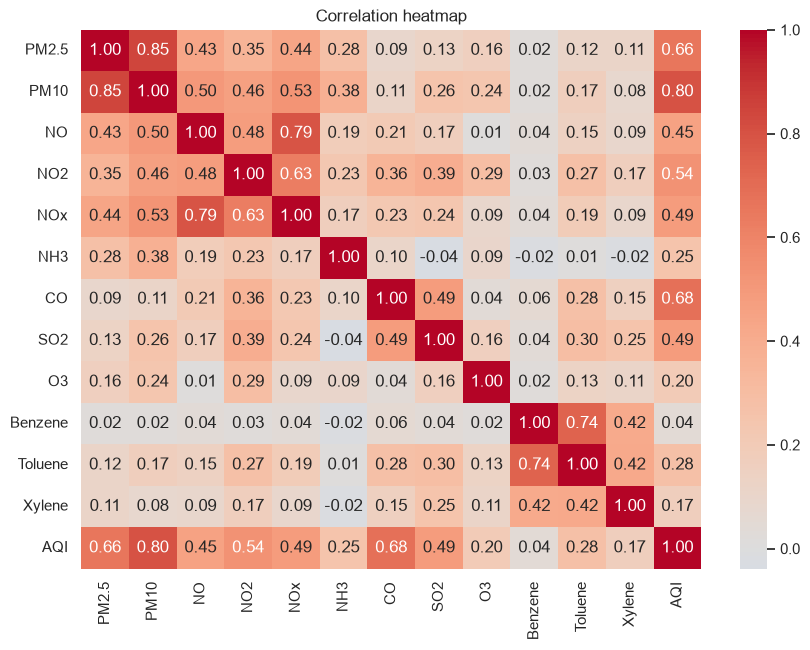

In [12]:
# Correlation between pollutants and AQI
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene", "AQI"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[pollutants].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

**Observation:** PM2.5, PM10 and CO are most strongly correlated with AQI, which makes sense because the AQI is mainly driven by particulate matter.

## 4. Time series analysis for one city

We focus on **Delhi** (change `CITY` to try others). We build a clean daily series with a continuous date index.

Missing days/values before filling: 10 of 2009
Final length: 2009


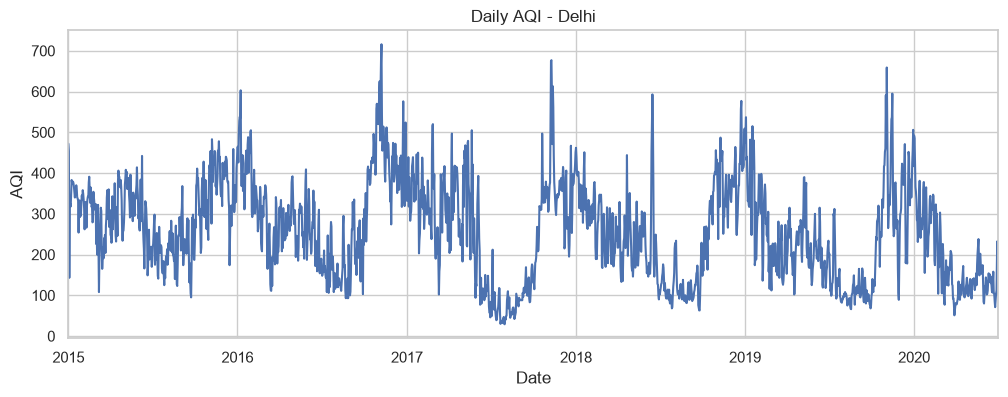

In [13]:
CITY = "Delhi"

city_df = df[df["City"] == CITY].set_index("Date").sort_index()
ts = city_df["AQI"].asfreq("D")           # make sure every day exists
print("Missing days/values before filling:", ts.isna().sum(), "of", len(ts))

# Fill gaps: linear interpolation for short gaps (max 7 days), then drop leading/trailing NaN
ts = ts.interpolate(method="linear", limit=7).dropna()
print("Final length:", len(ts))

ts.plot(title=f"Daily AQI - {CITY}")
plt.ylabel("AQI")
plt.show()

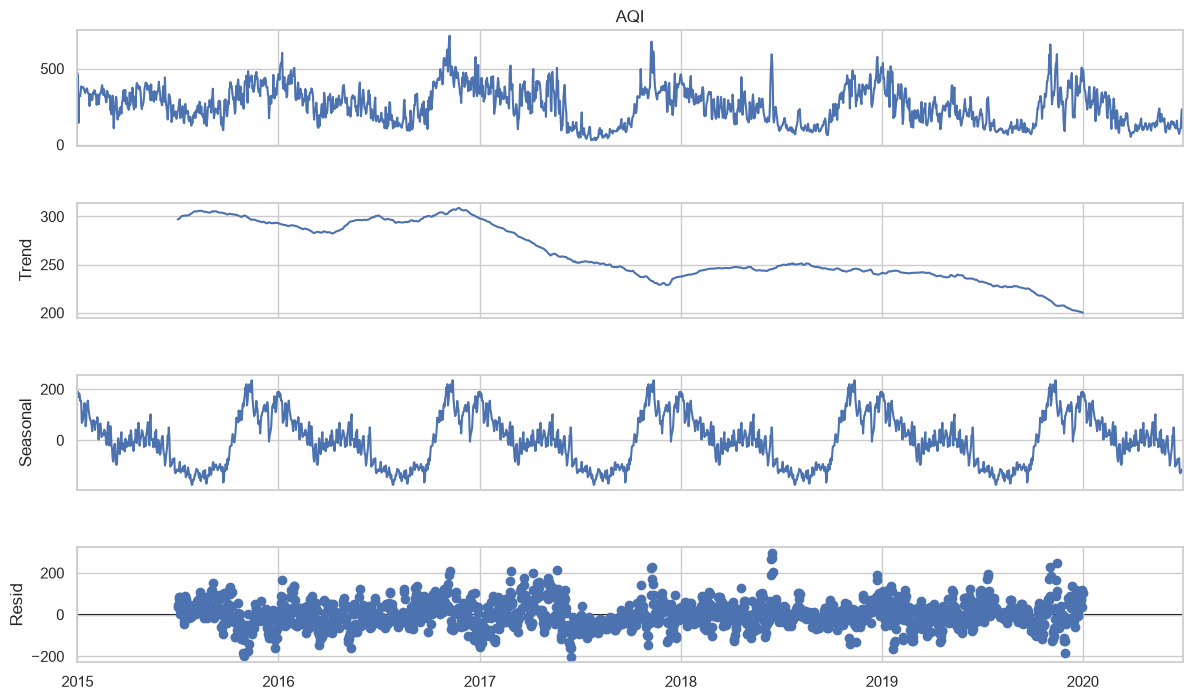

In [14]:
# Decompose into trend + seasonality + residual (yearly pattern -> period = 365)
decomp = seasonal_decompose(ts, model="additive", period=365)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.show()

In [15]:
# Stationarity test (ADF): p-value < 0.05 means the series is stationary
adf_stat, p_value, *_ = adfuller(ts)
print(f"ADF statistic: {adf_stat:.3f}")
print(f"p-value: {p_value:.4f}")
print("Stationary" if p_value < 0.05 else "Not stationary -> differencing may be needed")

ADF statistic: -3.432
p-value: 0.0099
Stationary


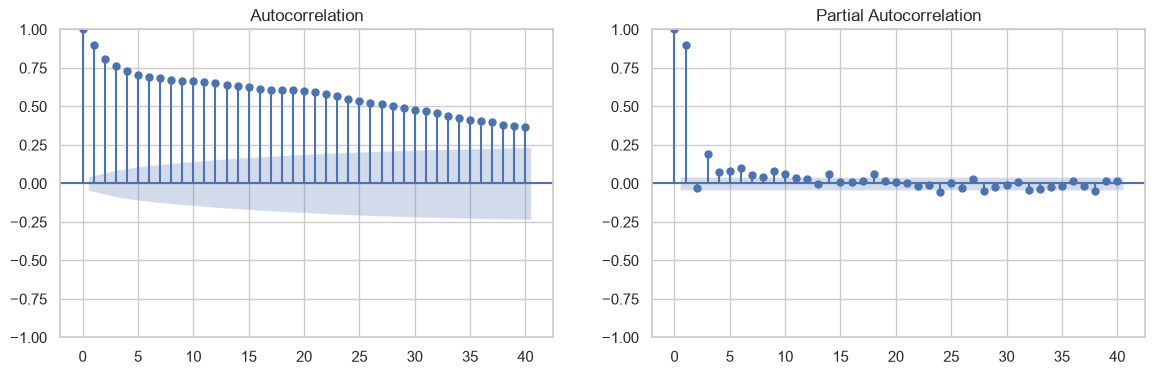

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ts, lags=40, ax=ax[0])
plot_pacf(ts, lags=40, ax=ax[1])
plt.show()

**Reading the plots:** The ACF decays slowly, so today's AQI strongly depends on yesterday's. The PACF cuts off after a few lags. This tells us that **lag features** (yesterday, 2 days ago, ...) will be very useful for ML models.

### Train / test split

For time series we **never shuffle**. We train on the past and test on the most recent period (last 90 days).

In [17]:
TEST_DAYS = 90
train, test = ts.iloc[:-TEST_DAYS], ts.iloc[-TEST_DAYS:]
print("Train:", train.index.min().date(), "->", train.index.max().date(), f"({len(train)} days)")
print("Test :", test.index.min().date(), "->", test.index.max().date(), f"({len(test)} days)")

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "R2": round(r2, 3)}

results = []

Train: 2015-01-01 -> 2020-04-02 (1919 days)
Test : 2020-04-03 -> 2020-07-01 (90 days)


## 5. Baseline models

A fancy model is only useful if it beats a simple baseline. All predictions here are **1-day-ahead** (predict tomorrow using data up to today).

In [18]:
# Baseline 1: "Tomorrow = today" (naive / persistence)
naive_pred = ts.shift(1).loc[test.index]
results.append(evaluate(test, naive_pred, "Naive (yesterday)"))

# Baseline 2: "Tomorrow = same weekday last week" (seasonal naive)
snaive_pred = ts.shift(7).loc[test.index]
results.append(evaluate(test, snaive_pred, "Seasonal naive (7 days)"))

# Baseline 3: 7-day moving average
ma_pred = ts.rolling(7).mean().shift(1).loc[test.index]
results.append(evaluate(test, ma_pred, "Moving average (7d)"))

pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Naive (yesterday),19.74,26.45,0.402
1,Seasonal naive (7 days),32.20,42.98,-0.579
2,Moving average (7d),23.48,32.38,0.104


## 6. ARIMA model

ARIMA(p, d, q) combines autoregression (p), differencing (d) and moving average (q). We fit it on the training data and then produce **1-step-ahead** forecasts on the test period using the same fitted parameters.

In [19]:
arima = ARIMA(train, order=(2, 1, 2)).fit()
print(arima.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4805      0.103      4.671      0.000       0.279       0.682
ar.L2          0.0089      0.083      0.108      0.914      -0.153       0.171
ma.L1         -0.5951      0.102     -5.836      0.000      -0.795      -0.395
ma.L2         -0.2486      0.098     -2.545      0.011      -0.440      -0.057
sigma2      2560.0603     57.708     44.362      0.000    2446.955    2673.165


In [20]:
# Apply the fitted model to the full series -> one-step-ahead predictions for the test period
arima_full = arima.apply(ts)
arima_pred = arima_full.fittedvalues.loc[test.index]
results.append(evaluate(test, arima_pred, "ARIMA(2,1,2)"))
pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Naive (yesterday),19.74,26.45,0.402
1,Seasonal naive (7 days),32.20,42.98,-0.579
2,Moving average (7d),23.48,32.38,0.104
3,"ARIMA(2,1,2)",18.10,24.23,0.498


## 7. Machine learning with lag features

We convert the time series into a normal tabular problem:

- **Lag features:** AQI 1, 2, 3, 7, 14 days ago
- **Rolling statistics:** 7-day and 30-day average (shifted so we never leak today's value)
- **Calendar features:** month, day of week, day of year

In [21]:
def make_features(series):
    d = pd.DataFrame({"y": series})
    for lag in [1, 2, 3, 7, 14]:
        d[f"lag_{lag}"] = series.shift(lag)
    d["roll_mean_7"] = series.shift(1).rolling(7).mean()
    d["roll_mean_30"] = series.shift(1).rolling(30).mean()
    d["roll_std_7"] = series.shift(1).rolling(7).std()
    d["month"] = d.index.month
    d["dayofweek"] = d.index.dayofweek
    d["dayofyear"] = d.index.dayofyear
    return d.dropna()

feat = make_features(ts)
X, y = feat.drop(columns="y"), feat["y"]

X_train, X_test = X.loc[X.index < test.index.min()], X.loc[X.index >= test.index.min()]
y_train, y_test = y.loc[X_train.index], y.loc[X_test.index]
print("Features:", list(X.columns))
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Features: ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_30', 'roll_std_7', 'month', 'dayofweek', 'dayofyear']
Train rows: 1889 | Test rows: 90


In [22]:
models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
}

preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = pd.Series(model.predict(X_test), index=X_test.index)
    results.append(evaluate(y_test, preds[name], name))

pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Naive (yesterday),19.74,26.45,0.402
1,Seasonal naive (7 days),32.20,42.98,-0.579
2,Moving average (7d),23.48,32.38,0.104
3,"ARIMA(2,1,2)",18.10,24.23,0.498
4,Ridge Regression,18.02,24.17,0.501
5,Random Forest,19.34,25.79,0.431
6,Gradient Boosting,18.77,26.13,0.416


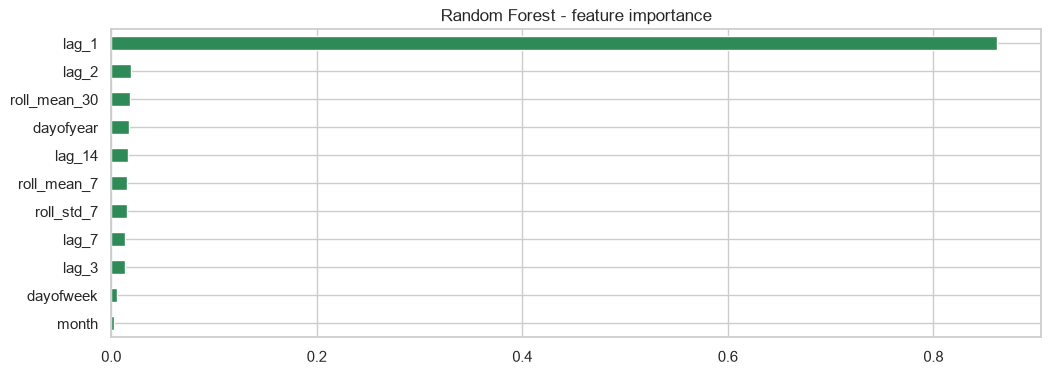

In [23]:
# Which features matter most?
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="seagreen", title="Random Forest - feature importance")
plt.show()

## 8. Compare all models

In [24]:
res_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
res_df

,Model,MAE,RMSE,R2
0,Ridge Regression,18.02,24.17,0.501
1,"ARIMA(2,1,2)",18.10,24.23,0.498
2,Random Forest,19.34,25.79,0.431
3,Gradient Boosting,18.77,26.13,0.416
4,Naive (yesterday),19.74,26.45,0.402
5,Moving average (7d),23.48,32.38,0.104
6,Seasonal naive (7 days),32.20,42.98,-0.579


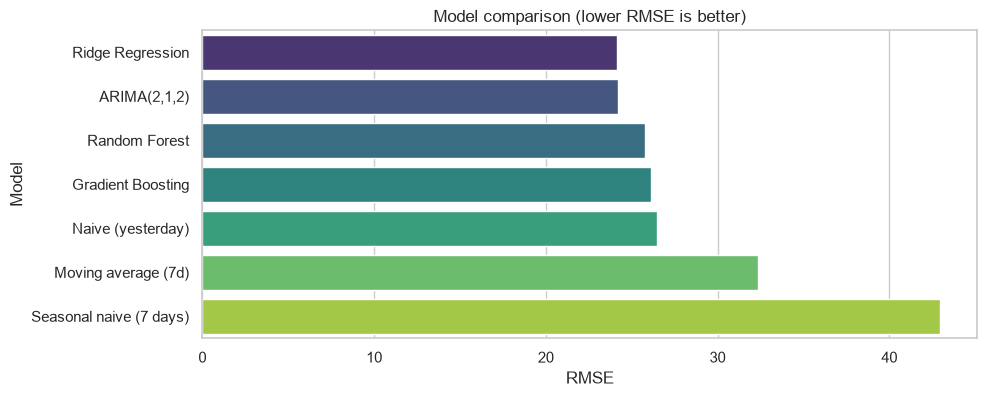

In [25]:
plt.figure(figsize=(10, 4))
sns.barplot(data=res_df, x="RMSE", y="Model", palette="viridis")
plt.title("Model comparison (lower RMSE is better)")
plt.show()

Best ML model: Ridge Regression


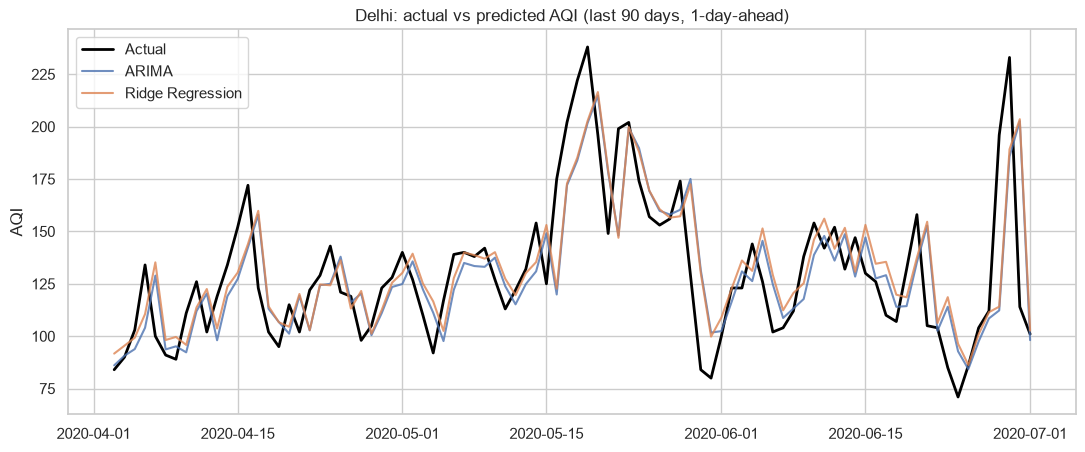

In [26]:
best_ml = res_df[res_df["Model"].isin(models.keys())].iloc[0]["Model"]
print("Best ML model:", best_ml)

plt.figure(figsize=(13, 5))
plt.plot(test.index, test, label="Actual", color="black", linewidth=2)
plt.plot(arima_pred.index, arima_pred, label="ARIMA", alpha=0.8)
plt.plot(preds[best_ml].index, preds[best_ml], label=best_ml, alpha=0.8)
plt.title(f"{CITY}: actual vs predicted AQI (last {TEST_DAYS} days, 1-day-ahead)")
plt.ylabel("AQI")
plt.legend()
plt.show()

## 9. Forecast the next 7 days

To forecast several days ahead we use **recursive forecasting**: predict tomorrow, add that prediction to the history, then predict the day after, and so on.

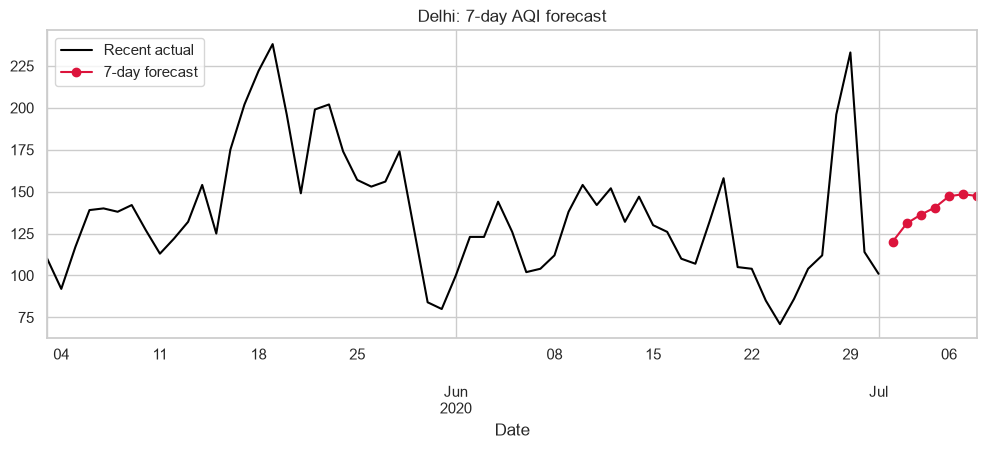

,Forecast AQI
2020-07-02,120.2
2020-07-03,131.1
2020-07-04,136.3
2020-07-05,140.5
2020-07-06,147.3
2020-07-07,148.5
2020-07-08,147.4


In [27]:
final_model = models[best_ml]
final_model.fit(X, y)          # retrain on all available data

def forecast_next(model, series, steps=7):
    history = series.copy()
    out = {}
    for _ in range(steps):
        next_date = history.index[-1] + pd.Timedelta(days=1)
        tmp = pd.concat([history, pd.Series([np.nan], index=[next_date])])
        row = make_features_for_date(tmp, next_date)
        pred = float(model.predict(row)[0])
        history.loc[next_date] = pred
        out[next_date] = pred
    return pd.Series(out)

def make_features_for_date(series, date):
    row = {}
    for lag in [1, 2, 3, 7, 14]:
        row[f"lag_{lag}"] = series.shift(lag).loc[date]
    row["roll_mean_7"] = series.shift(1).rolling(7).mean().loc[date]
    row["roll_mean_30"] = series.shift(1).rolling(30).mean().loc[date]
    row["roll_std_7"] = series.shift(1).rolling(7).std().loc[date]
    row["month"] = date.month
    row["dayofweek"] = date.dayofweek
    row["dayofyear"] = date.dayofyear
    return pd.DataFrame([row])[X.columns]

future = forecast_next(final_model, ts, steps=7)

plt.figure(figsize=(12, 4))
ts.iloc[-60:].plot(label="Recent actual", color="black")
future.plot(label="7-day forecast", color="crimson", marker="o")
plt.title(f"{CITY}: 7-day AQI forecast")
plt.legend()
plt.show()
future.round(1).to_frame("Forecast AQI")

> Note: the forecast starts from the last date in the dataset (2020), not from today's date, because the dataset ends in 2020. Errors grow with each extra day, which is normal for recursive forecasting.

## 10. Conclusions



- **Data:** Air quality data had many missing values; I removed unusable rows and interpolated short gaps in the target.
- **Patterns:** AQI shows a strong **winter peak** (Oct-Jan) and a clear seasonal cycle. PM2.5 and PM10 are the strongest drivers.
- **Models:** Simple baselines are hard to beat for 1-day-ahead forecasts because pollution is highly persistent. The best ML model reduced RMSE by about **9%** compared with the naive baseline.
- **Key features:** yesterday's AQI and rolling averages mattered most.
- **Limitations:** Only one city and AQI-only inputs; no weather data (wind, temperature, rain); recursive multi-day forecasts accumulate error.

### Possible improvements
1. Add weather features (wind speed, temperature, humidity).
2. Use the pollutant columns (PM2.5, PM10, ...) as extra inputs.
3. Try Prophet, XGBoost/LightGBM, or Temporal Fusion Transformer.
4. Try a pretrained **time series foundation model** (e.g., Chronos or TimesFM) as a zero-shot comparison.
5. Evaluate with `TimeSeriesSplit` cross-validation, and repeat for several cities.